In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score , precision_score, recall_score, f1_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df= pd.read_csv("ai4i2020.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [ ]:
df["Machine failure"].value_counts(normalize=True) * 100

,proportion
Machine failure,
0,96.61
1,3.39


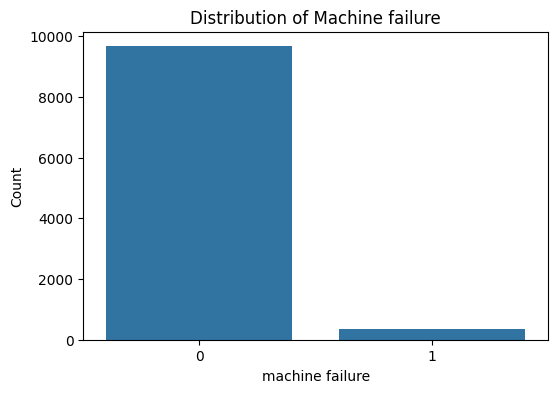

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x="Machine failure", data=df)
plt.title("Distribution of Machine failure")
plt.xlabel("machine failure")
plt.ylabel("Count")
plt.show()

In [ ]:
X= df.drop("Machine failure", axis=1)
y= df["Machine failure"]

In [ ]:
print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (10000, 13)
Output Shape: (10000,)


In [ ]:
categorical_features = ["Type"]
numerical_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ])


Kernel Linear

In [ ]:
linear_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='linear'))
])

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear = linear_svm.predict(X_test)

In [ ]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear,  zero_division=0)

print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 Score:", f1_linear)

Accuracy: 0.9695
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [ ]:
print(classification_report(y_test, y_pred_linear, target_names= ["No Failure", "Failure"], zero_division=0 ))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1939
     Failure       0.00      0.00      0.00        61

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.94      0.97      0.95      2000



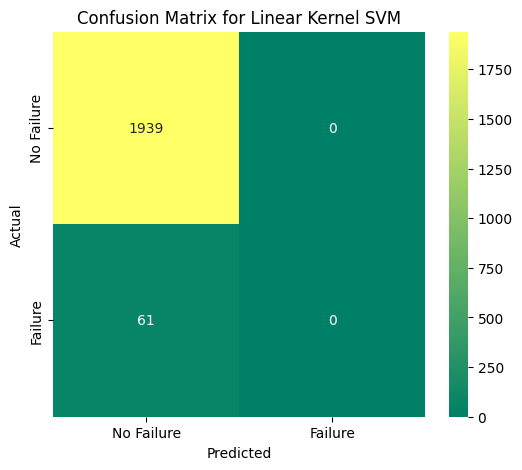

In [ ]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6,5))

sns.heatmap(cm_linear,annot=True,fmt="d",cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Linear Kernel SVM")
plt.show()

Kernel rbf

In [ ]:
rbf_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf'))
])

rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf = rbf_svm.predict(X_test)

In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf,  zero_division=0)

print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 Score:", f1_rbf)

Accuracy: 0.977
Precision: 0.8571428571428571
Recall: 0.29508196721311475
F1 Score: 0.43902439024390244


In [ ]:
print(classification_report(y_test, y_pred_rbf, target_names= ["No Failure", "Failure"], zero_division=0 ))

              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1939
     Failure       0.86      0.30      0.44        61

    accuracy                           0.98      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.98      0.97      2000



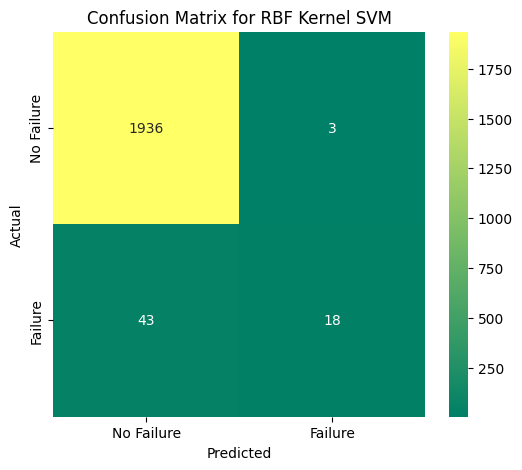

In [ ]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6,5))

sns.heatmap(cm_rbf,annot=True,fmt="d",cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for RBF Kernel SVM")
plt.show()

Poly kernel

In [ ]:
poly_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='poly'))
])

poly_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='poly'))])

In [ ]:
y_pred_poly = poly_svm.predict(X_test)

In [ ]:
accuracy_poly = accuracy_score(y_test, y_pred_poly)
precision_poly = precision_score(y_test, y_pred_poly, zero_division=0)
recall_poly = recall_score(y_test, y_pred_poly, zero_division=0)
f1_poly = f1_score(y_test, y_pred_poly,  zero_division=0)

print("Accuracy:", accuracy_poly)
print("Precision:", precision_poly)
print("Recall:", recall_poly)
print("F1 Score:", f1_poly)

Accuracy: 0.9795
Precision: 0.75
Recall: 0.4918032786885246
F1 Score: 0.594059405940594


In [ ]:
print(classification_report(y_test, y_pred_poly, target_names= ["No Failure", "Failure"], zero_division=0 ))

              precision    recall  f1-score   support

  No Failure       0.98      0.99      0.99      1939
     Failure       0.75      0.49      0.59        61

    accuracy                           0.98      2000
   macro avg       0.87      0.74      0.79      2000
weighted avg       0.98      0.98      0.98      2000



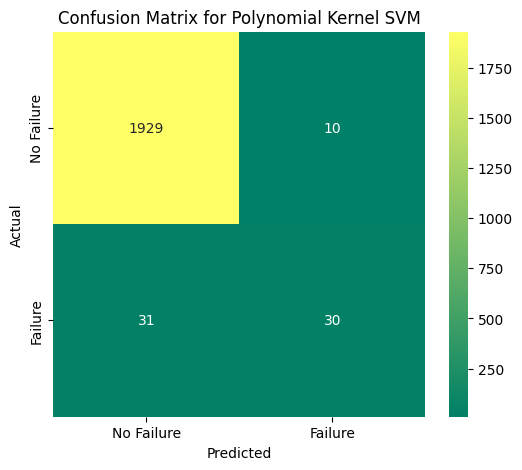

In [ ]:
cm_poly = confusion_matrix(y_test, y_pred_poly)

plt.figure(figsize=(6,5))

sns.heatmap(cm_poly,annot=True,fmt="d",cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Polynomial Kernel SVM")
plt.show()

Sigmoid kernal

In [ ]:
sigmoid_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='sigmoid'))
])

sigmoid_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='sigmoid'))])

In [ ]:
y_pred_sigmoid = sigmoid_svm.predict(X_test)

In [ ]:
accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
precision_sigmoid = precision_score(y_test, y_pred_sigmoid, zero_division=0)
recall_sigmoid = recall_score(y_test, y_pred_sigmoid, zero_division=0)
f1_sigmoid = f1_score(y_test, y_pred_sigmoid,  zero_division=0)

print("Accuracy:", accuracy_sigmoid)
print("Precision:", precision_sigmoid)
print("Recall:", recall_sigmoid)
print("F1 Score:", f1_sigmoid)

Accuracy: 0.9525
Precision: 0.22580645161290322
Recall: 0.22950819672131148
F1 Score: 0.22764227642276422


In [ ]:
print(classification_report(y_test, y_pred_sigmoid, target_names= ["No Failure", "Failure"], zero_division=0 ))

              precision    recall  f1-score   support

  No Failure       0.98      0.98      0.98      1939
     Failure       0.23      0.23      0.23        61

    accuracy                           0.95      2000
   macro avg       0.60      0.60      0.60      2000
weighted avg       0.95      0.95      0.95      2000



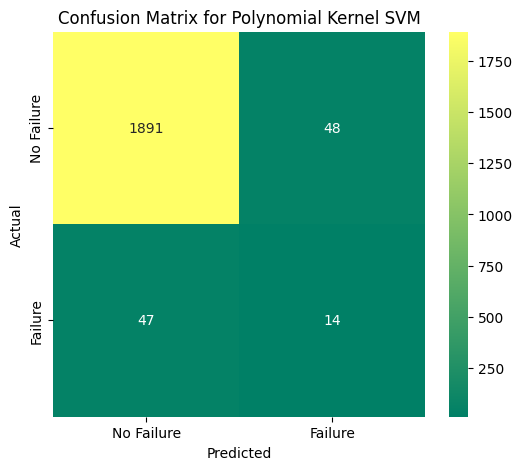

In [ ]:
cm_sigmoid = confusion_matrix(y_test, y_pred_sigmoid)

plt.figure(figsize=(6,5))

sns.heatmap(cm_sigmoid,annot=True,fmt="d",cmap="summer", xticklabels=["No Failure", "Failure"], yticklabels=["No Failure", "Failure"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Polynomial Kernel SVM")
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_poly, accuracy_sigmoid],
    "Precision": [precision_linear, precision_rbf, precision_poly, precision_sigmoid],
    "Recall": [recall_linear, recall_rbf, recall_poly, recall_sigmoid],
    "F1 Score": [f1_linear, f1_rbf, f1_poly, f1_sigmoid]
})

comparison

,Accuracy,Precision,Recall,F1 Score
0,0.9695,0.000000,0.000000,0.000000
1,0.9770,0.857143,0.295082,0.439024
2,0.9795,0.750000,0.491803,0.594059
3,0.9525,0.225806,0.229508,0.227642


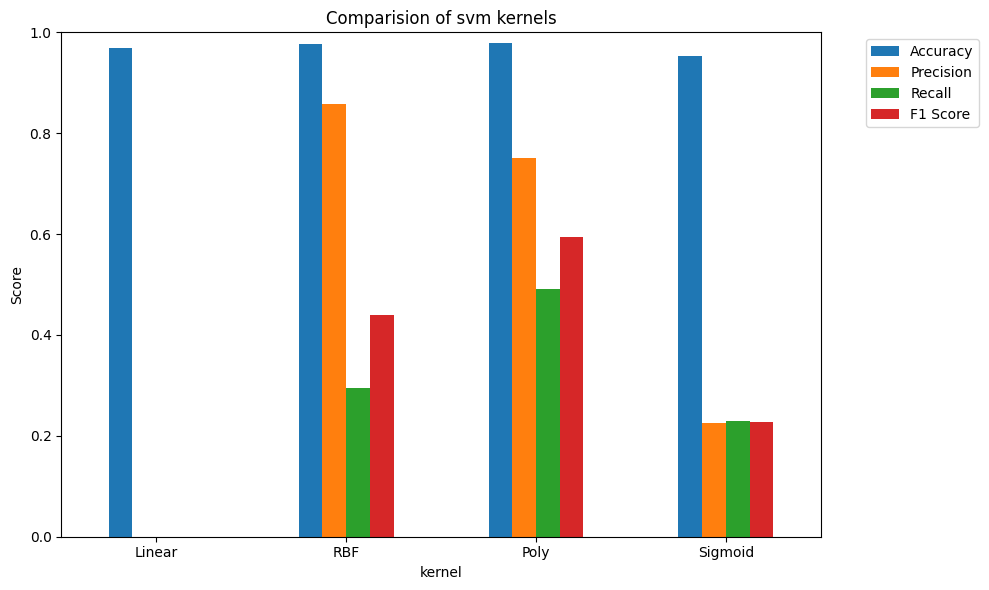

In [ ]:
comparison["kernel"] = ["Linear", "RBF", "Poly", "Sigmoid"]
comparison_plot = comparison.set_index("kernel")
comparison_plot.plot(kind="bar", figsize=(10,6))
plt.title("Comparision of svm kernels")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Hyperparamter Tuning

In [ ]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(steps = [('preprocessor', preprocessor),
                            ('classifier', SVC())])

In [ ]:
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

In [ ]:
grid_search = GridSearchCV(estimator=pipeline,param_grid=param_grid,cv=5,scoring="f1",n_jobs=-1,verbose=1)

In [ ]:
grid_search.fit(X_train, y_train)

print("best parameters:")
print(grid_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
best parameters:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [ ]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

In [ ]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

print("tuned SVM Results")
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)